# Issue 4: ¿Los nulos son MCAR respecto al target?

Este notebook continúa [issue3.ipynb](issue3.ipynb), que a su vez ejecuta [issue2.ipynb](issue2.ipynb): usa su `X_train` y `y_train`, ya sin las columnas redundantes del Issue 3. Solo se usa entrenamiento.

Pasos:

1. Para cada columna con nulos, comparar la tasa de `Charged Off` entre filas con nulo y sin nulo.
2. Decidir si el nulo es MCAR respecto al target.
3. Según el porcentaje de nulos, decidir si se imputa o si hay que evaluar la columna.

> **Antes de ejecutar:** este notebook necesita el dataset de la base común (Issue 2). La celda siguiente ejecuta `issue3.ipynb`, que ejecuta `issue2.ipynb` (carga con `src/data.py`) y quita las columnas redundantes.
>
> **Para el Issue 5:** la columna `decisión` de la tabla final (también registrada en `reports/decisiones_columnas.md`) es el punto de partida para la imputación. El Issue 5 empieza con `%run issue4.ipynb` y tiene `tabla` disponible.

Filas en df_work: 1,348,059
Columnas en df_work: 104
¿Existe 'target' en df_work?: True
Columnas excluidas por src/data.py: 48
Columnas excluidas que siguen presentes: []
Filas totales: 1,348,059
Columnas totales: 104

=== TIPOS DE DATOS ===
float64           86
object            15
datetime64[ns]     1
int8               1
category           1
Name: count, dtype: int64


target
0    1078739
1     269320
Name: count, dtype: int64
Tasa de Charged Off: 0.1998


Entrenamiento: 862,757 filas, 101 columnas, Charged Off 19.98%
Validación: 215,690 filas, 101 columnas, Charged Off 19.98%
Prueba: 269,612 filas, 101 columnas, Charged Off 19.98%


Columnas finales: 76
X_train: (862757, 76) | X_val: (215690, 76) | X_test: (269612, 76)


Entrenamiento: 862,757 préstamos, 100 columnas candidatas
Charged Off en entrenamiento: 19.98%
numérica            85
categórica/texto    15
Ninguna de las 48 columnas excluidas está en X_ent.


Columnas 100 % vacías: ninguna

Casi constantes (dominancia >= 99%); tasa global de Charged Off = 19.98%
36 columnas con 50 % a 99.9 % de nulos (quedan para el Issue 5):


Figura guardada en reports/figures/redundancia_dominancia.png


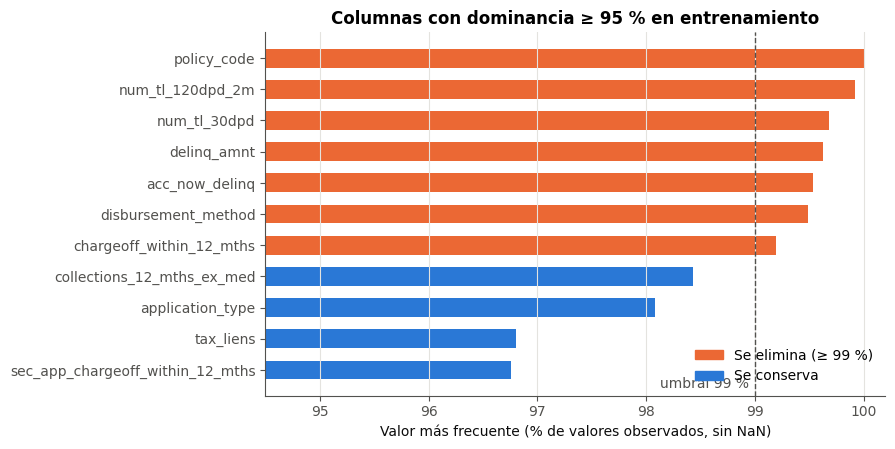

Grupos de columnas idénticas: ninguno


Figura guardada en reports/figures/redundancia_pares_semilla.png


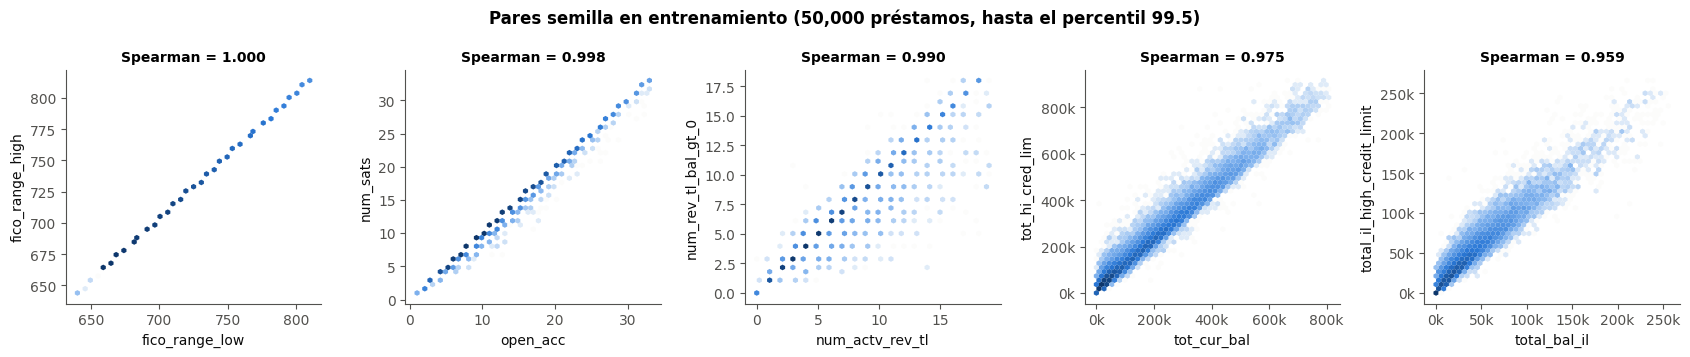

Figura guardada en reports/figures/redundancia_correlacion.png


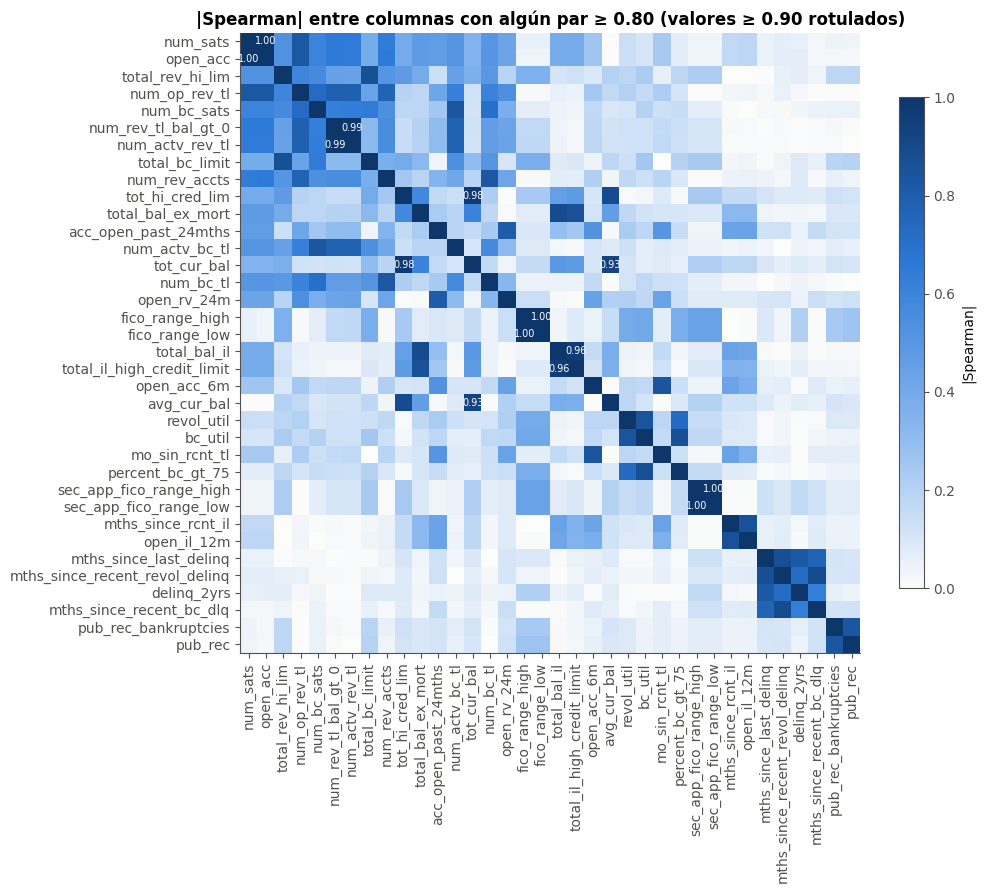

fico_range_high - fico_range_low:
4.0    99.986
5.0     0.014

open_acc - num_sats: igual en 96.3%; difiere en 1 o más en 3.7%

    columna                                       fórmula aproximada  pearson
avg_cur_bal                                   tot_cur_bal / open_acc   0.9943
 revol_util                       100 · revol_bal / total_rev_hi_lim   0.9814
    bc_util 100 · (total_bc_limit - bc_open_to_buy) / total_bc_limit   0.9639

application_type frente a la presencia de annual_inc_joint:


annual_inc_joint no nulo   False  True 
application_type                       
Individual                846186      0
Joint App                      0  16571


Los 50 títulos más frecuentes cubren el 91.6% de los préstamos con título.


term                           2
application_type               2
verification_status_joint      3
verification_status            3
home_ownership                 6
emp_length                    11
purpose                       14
title                         51
addr_state                    51
zip_code                     934



Pares con mayor V de Cramér corregida:
zip_code             addr_state                   0.994
purpose              title                        0.861
verification_status  verification_status_joint    0.605
home_ownership       zip_code                     0.162
term                 verification_status          0.134
emp_length           verification_status_joint    0.115
home_ownership       addr_state                   0.112
verification_status  title                        0.108


Figura guardada en reports/figures/redundancia_cramer.png


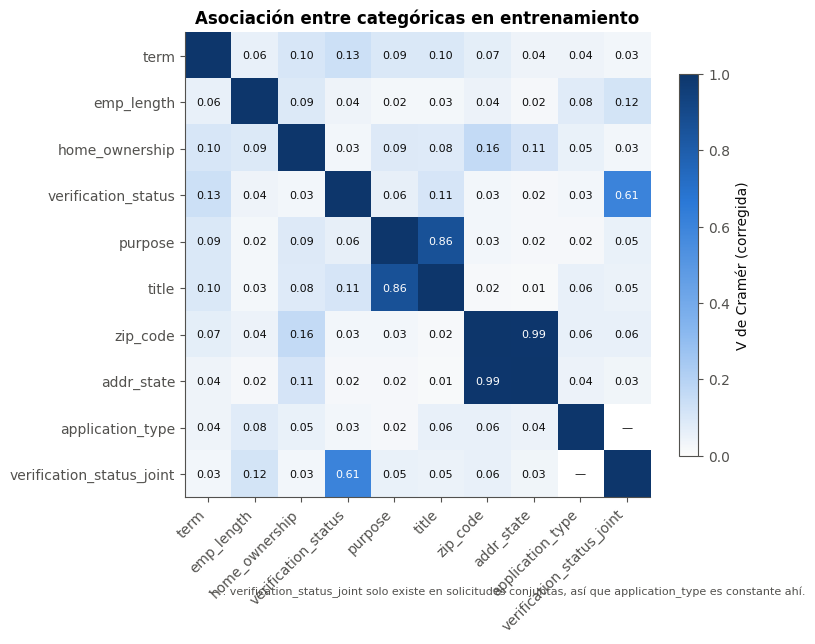

V de Cramér (purpose, title):  0.861


U(purpose | title) = 0.859  -> cuánto de purpose explica title


U(title | purpose) = 0.661  -> cuánto de title explica purpose
Nulos: purpose 0.00%, title 1.24%


U(addr_state | zip_code) = 0.997


U(zip_code | addr_state) = 0.541
Códigos zip3 asociados a más de un estado: 55.8%

V de Cramér (verification_status, verification_status_joint), solo conjuntas: 0.605


Se eliminan 14 de 100 columnas; quedan 86.


Redundantes quitadas de X_train: ['fico_range_high', 'tot_cur_bal', 'total_bal_il', 'num_rev_tl_bal_gt_0', 'num_sats', 'num_tl_120dpd_2m', 'num_tl_30dpd']
X_train: (862757, 69) | X_val: (215690, 69) | X_test: (269612, 69)


In [1]:
%run issue3.ipynb

## 1. Relación de cada nulo con el target

Si el nulo es aleatorio (MCAR), la tasa de `Charged Off` debería ser casi la misma con y sin nulo.

Con 862,757 filas, la prueba chi-cuadrado da p-valor ≈ 0 para casi cualquier diferencia, así que no sirve para decidir. Se usa el tamaño de la diferencia:

- **MCAR:** la tasa de `Charged Off` cambia menos de **2 puntos porcentuales** (10 % de la tasa base de ~20 %).
- **No MCAR:** cambia 2 puntos o más.
- **Pocos nulos:** con menos de 1,000 nulos la tasa con nulo es muy inestable y no se juzga.

In [2]:
cols_con_nulos = X_train.columns[X_train.isna().any()]

filas = []
for col in cols_con_nulos:
    es_nulo = X_train[col].isna()
    filas.append({
        'columna': col,
        'nulos': es_nulo.sum(),
        '% nulos': es_nulo.mean() * 100,
        'CO con nulo (%)': y_train[es_nulo].mean() * 100,
        'CO sin nulo (%)': y_train[~es_nulo].mean() * 100,
    })

tabla = pd.DataFrame(filas).set_index('columna')
tabla['diferencia (pp)'] = tabla['CO con nulo (%)'] - tabla['CO sin nulo (%)']
tabla['MCAR'] = np.where(tabla['diferencia (pp)'].abs() < 2, 'Sí', 'No')
tabla.loc[tabla['nulos'] < 1000, 'MCAR'] = 'Pocos nulos'

## 2. Decisión según el porcentaje de nulos

| % nulos | Decisión |
|---|---|
| ≤ 40 % | **Imputar.** Si no es MCAR, añadir además un indicador de nulo para no perder esa información. |
| > 40 % | **Evaluar.** Imputar más del 40 % de una columna inventa demasiados datos; hay que comparar en validación si conviene eliminarla o conservarla con indicador de nulo (Issue 5). |

In [3]:
def decidir(fila):
    if fila['% nulos'] > 40:
        return 'Evaluar'
    if fila['MCAR'] == 'No':
        return 'Imputar + indicador'
    return 'Imputar'

tabla['decisión'] = tabla.apply(decidir, axis=1)
tabla = tabla.sort_values('% nulos', ascending=False)

pd.set_option('display.max_rows', 100)
tabla.round(1)

,nulos,% nulos,CO con nulo (%),CO sin nulo (%),diferencia (pp),MCAR,decisión
columna,,,,,,,
mths_since_last_record,715999,83.0,19.4,22.8,-3.4,No,Evaluar
mths_since_recent_bc_dlq,658549,76.3,19.7,21.0,-1.3,Sí,Evaluar
mths_since_last_major_derog,636288,73.8,19.3,21.9,-2.6,No,Evaluar
mths_since_recent_revol_delinq,574504,66.6,19.6,20.6,-1.0,Sí,Evaluar
il_util,564647,65.4,18.6,22.5,-3.9,No,Evaluar
mths_since_rcnt_il,527569,61.1,18.6,22.2,-3.7,No,Evaluar
all_util,518566,60.1,18.4,22.3,-3.9,No,Evaluar
open_acc_6m,518528,60.1,18.4,22.3,-3.9,No,Evaluar
total_cu_tl,518528,60.1,18.4,22.3,-3.9,No,Evaluar


In [4]:
pd.crosstab(tabla['decisión'], tabla['MCAR'], margins=True, margins_name='Total')

MCAR,No,Pocos nulos,Sí,Total
decisión,,,,
Evaluar,15,0,3,18
Imputar,0,12,0,12
Imputar + indicador,30,0,0,30
Total,45,12,3,60


## Conclusión

De las 60 columnas con nulos en `X_train` (ya sin las redundantes del Issue 3):

- **45 no son MCAR:** la tasa de `Charged Off` cambia 2 puntos o más cuando falta el dato. Ejemplos: `emp_length` (27.0 % con nulo frente a 19.5 % sin nulo) y el grupo de 18 columnas del buró con 5.2 % de nulos (15.7 % frente a 20.2 %).
- **3 son MCAR:** `mths_since_last_delinq`, `mths_since_recent_bc_dlq` y `mths_since_recent_revol_delinq`.
- **12 tienen pocos nulos** (menos de 1,000, por debajo de 0.2 %): se imputan sin más.

Decisiones:

| Decisión | Columnas | Qué sigue en el Issue 5 |
|---|---|---|
| Imputar | 12 | Imputación simple (mediana o moda), ajustada solo con entrenamiento. |
| Imputar + indicador | 30 | Imputación simple y una columna `<nombre>_nulo` con 1 si faltaba el dato. |
| Evaluar | 18 | Tienen más de 40 % de nulos: comparar en validación si conviene eliminarlas o conservarlas con indicador. |

**Advertencia:** muchas columnas solo empezaron a registrarse en 2012 o a finales de 2015, así que su nulo también indica que el préstamo es antiguo. Parte de la diferencia en `Charged Off` puede deberse al año y no al nulo. Conviene tenerlo en cuenta al comparar opciones en el Issue 5.
